In [1]:

import pandas as pd

df = pd.read_csv("train.csv")

print(df.head())
print(df.shape)
print(df.columns)


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [2]:

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin      

In [3]:

# Make a copy of the original dataset
titanic_clean = df.copy()

# Check missing values
print(titanic_clean.isnull().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [4]:

# Fill missing Age values with the median
titanic_clean["Age"] = titanic_clean["Age"].fillna(
    titanic_clean["Age"].median()
)

# Fill missing Embarked values with the most common value
titanic_clean["Embarked"] = titanic_clean["Embarked"].fillna(
    titanic_clean["Embarked"].mode()[0]
)

# Create a column to record whether cabin information exists
titanic_clean["CabinKnown"] = titanic_clean["Cabin"].notna().astype(int)

# Remove the original Cabin column
titanic_clean = titanic_clean.drop(columns=["Cabin"])

# Check missing values after cleaning
print("Missing values after cleaning:")
print(titanic_clean.isnull().sum())


Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
CabinKnown     0
dtype: int64


In [5]:

# Count passengers who survived and did not survive
print("Survival Count:")
print(titanic_clean["Survived"].value_counts())

# Calculate survival percentage
print("\nSurvival Percentage:")
print(
    (titanic_clean["Survived"].value_counts(normalize=True) * 100).round(2)
)


Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


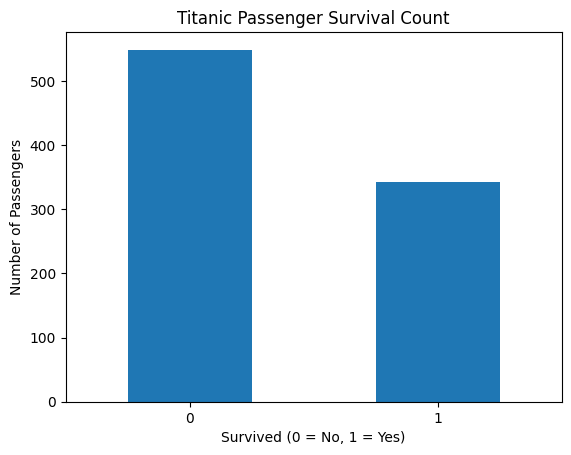

In [6]:

import matplotlib.pyplot as plt

survival_counts = titanic_clean["Survived"].value_counts().sort_index()

survival_counts.plot(kind="bar")
plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()


In [7]:

# Calculate survival rate by gender
gender_survival = titanic_clean.groupby("Sex")["Survived"].mean() * 100

print("Survival Rate by Gender (%):")
print(gender_survival.round(2))


Survival Rate by Gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


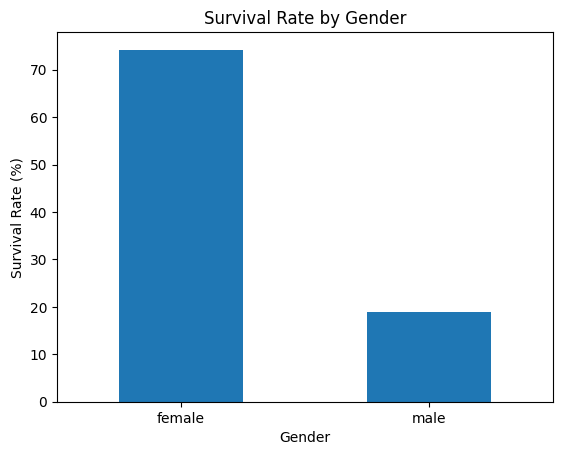

In [8]:

gender_survival.plot(kind="bar")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()


In [9]:

# Calculate survival rate by passenger class
class_survival = titanic_clean.groupby("Pclass")["Survived"].mean() * 100

print("Survival Rate by Passenger Class (%):")
print(class_survival.round(2))


Survival Rate by Passenger Class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


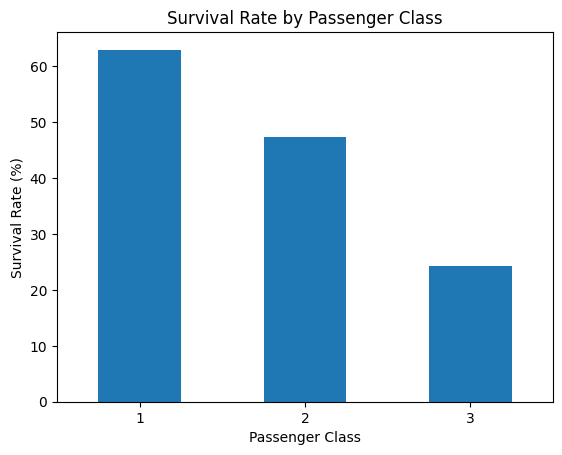

In [10]:

class_survival.plot(kind="bar")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()


In [11]:

# Divide passengers into age groups
titanic_clean["AgeGroup"] = pd.cut(
    titanic_clean["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

# Calculate survival rate for each age group
age_survival = titanic_clean.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print("Survival Rate by Age Group (%):")
print(age_survival.round(2))


Survival Rate by Age Group (%):
AgeGroup
Child          57.97
Teenager       42.86
Young Adult    35.33
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64


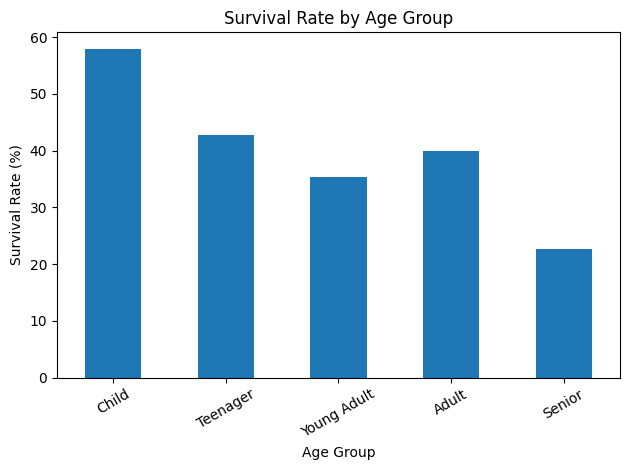

In [12]:

age_survival.plot(kind="bar")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [13]:

print("TITANIC DATA ANALYSIS - KEY INSIGHTS")

total_passengers = len(titanic_clean)
survived = int(titanic_clean["Survived"].sum())
not_survived = total_passengers - survived

print("Total passengers:", total_passengers)
print("Survived:", survived)
print("Did not survive:", not_survived)
print("Overall survival rate:",
      round(survived / total_passengers * 100, 2), "%")

print("\nSurvival rate by gender (%):")
print((titanic_clean.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by passenger class (%):")
print((titanic_clean.groupby("Pclass")["Survived"].mean() * 100).round(2))


TITANIC DATA ANALYSIS - KEY INSIGHTS
Total passengers: 891
Survived: 342
Did not survive: 549
Overall survival rate: 38.38 %

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


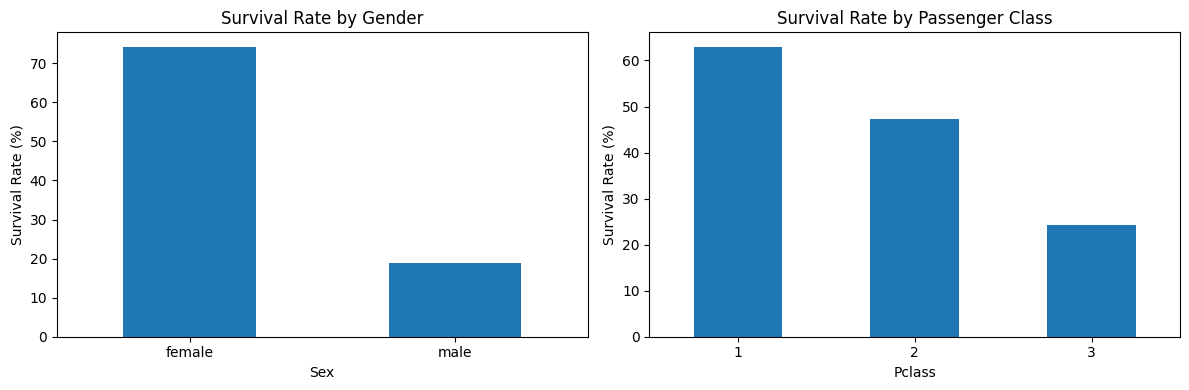

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

(titanic_clean.groupby("Sex")["Survived"].mean() * 100).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Survival Rate by Gender")
axes[0].set_ylabel("Survival Rate (%)")
axes[0].tick_params(axis="x", rotation=0)

(titanic_clean.groupby("Pclass")["Survived"].mean() * 100).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_ylabel("Survival Rate (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [15]:

titanic_clean.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [16]:

from google.colab import files
files.download("titanic_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>